# Pipeline CPU n°1 : PyTorch → ONNX → OpenVINO
TP1 Déploiement IA — ResNet-18 / CIFAR-10. **Environnement d'exécution Colab : CPU (Exécution > Modifier le type d'exécution > CPU).**

| Niveau | Composant |
|---|---|
| Haut niveau | PyTorch (ResNet-18 pré-entraîné) |
| Format | ONNX (opset 17) |
| Middle level | OpenVINO Runtime : fusions d'opérateurs, choix des kernels |
| Bas niveau | kernels CPU oneDNN (JIT AVX2/AVX-512) |
| Matériel | CPU Google Colab |

[Ouvrir dans Colab](https://colab.research.google.com/github/Romain-LM-Dev/TP1_deploiement_IA/blob/main/notebooks/01_cpu_openvino.ipynb)

## Protocole (identique aux 4 pipelines, défini dans `common.py`)
- **Données** : les 50 premières images du jeu de test CIFAR-10, redimensionnées de 32×32 à 224×224 (bilinéaire) puis normalisées avec la moyenne/écart-type ImageNet.
- **Modèle** : ResNet-18 pré-entraîné ImageNet (`IMAGENET1K_V1`). Les 1000 classes sont regroupées en 10 classes CIFAR (ex. les 118 races de chiens → *dog*) ; la classe prédite est celle dont le meilleur logit est le plus élevé.
- **Mesure** : batchs de 10 images, données déjà sur le périphérique, 1 appel initial (compilation éventuelle, chronométré à part), 3 passes de chauffe, puis 10 exécutions mesurées des 50 images. Synchronisation explicite après chaque batch sur GPU.
- **Énergie** : compteur matériel (NVML sur GPU, RAPL sur CPU si accessible), intégré sur ≥ 3 s d'inférence en boucle après chaque exécution.
- **Référence** : PyTorch *eager* sur le même matériel, pour mesurer le gain et vérifier que les prédictions ne sont pas dégradées.

In [1]:
!pip install -q openvino onnx

In [2]:
# Récupération du dépôt : code commun (données, modèle, protocole de mesure)
import os, subprocess, sys
REPO = "https://github.com/Romain-LM-Dev/TP1_deploiement_IA.git"
if os.path.exists("../common.py"):          # exécution locale depuis notebooks/
    os.chdir("..")
elif not os.path.exists("common.py"):       # Google Colab
    if not os.path.exists("TP1_deploiement_IA"):
        subprocess.run(["git", "clone", "-q", REPO], check=True)
    os.chdir("TP1_deploiement_IA")
sys.path.insert(0, os.getcwd())
import common as C
C.env_info()

{'python': '3.13.18',
 'torch': '2.11.0+cpu',
 'torchvision': '0.26.0+cpu',
 'cpu': 'Intel(R) Xeon(R) CPU @ 2.20GHz',
 'cpu_threads': 1,
 'os_cpu_count': 2}

In [3]:
import time
from collections import Counter
import numpy as np, torch
from IPython.display import display

torch.manual_seed(C.SEED)
x, y = C.load_data()            # (50, 3, 224, 224), normalisation ImageNet
model = C.load_model()          # ResNet-18 IMAGENET1K_V1, mode eval
print("Entrée :", tuple(x.shape), "| batch :", C.BATCH_SIZE, "| répétitions :", C.N_RUNS)
print("Répartition des classes :", dict(zip(C.CIFAR_CLASSES, np.bincount(y, minlength=10).tolist())))
results = []

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 175MB/s]


Entrée : (50, 3, 224, 224) | batch : 10 | répétitions : 10
Répartition des classes : {'airplane': 5, 'automobile': 3, 'bird': 2, 'cat': 3, 'deer': 5, 'dog': 7, 'frog': 9, 'horse': 4, 'ship': 4, 'truck': 8}


In [4]:
meter = C.EnergyMeter("cpu")
print("Source énergie :", meter.source)

Pas de mesure d'énergie CPU (RAPL inaccessible) : [Errno 2] No such file or directory: '/sys/class/powercap/intel-rapl:0/energy_uj'
Source énergie : None


## 1. Référence : PyTorch eager sur CPU

In [5]:
with torch.inference_mode():
    eager = C.benchmark("CPU-1 OpenVINO", "PyTorch eager (réf.)", model, C.make_batches(x), y, meter=meter)
ref = eager["_logits"]
results.append(eager)

PyTorch eager (réf.)             13.1 ±    1.3 img/s |   3864.9 ±  405.1 ms / 50 img | acc 64%


## 2. Export ONNX
Le graphe PyTorch est figé dans un format d'échange standard, indépendant du framework.

In [6]:
import onnx
onnx_path = C.export_onnx(model)
onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)
print(len(onnx_model.graph.node), "nœuds ONNX :", dict(Counter(n.op_type for n in onnx_model.graph.node)))

49 nœuds ONNX : {'Conv': 20, 'Relu': 17, 'MaxPool': 1, 'Add': 8, 'GlobalAveragePool': 1, 'Flatten': 1, 'Gemm': 1}


## 3. Compilation OpenVINO (middle level)
`compile_model` applique les transformations de graphe (fusion Conv+BatchNorm+ReLU, Conv+Add, réordonnancement mémoire) puis sélectionne pour chaque couche un kernel oneDNN adapté au jeu d'instructions du CPU. La précision est forcée en FP32 pour une comparaison équitable (OpenVINO passe sinon en BF16 sur les CPU qui le supportent).

In [7]:
import openvino as ov
core = ov.Core()
print(core.get_property("CPU", "FULL_DEVICE_NAME"), "| OpenVINO", ov.__version__)
t0 = time.perf_counter()
ov_model = core.read_model(onnx_path)
compiled = core.compile_model(ov_model, "CPU", {"PERFORMANCE_HINT": "LATENCY", "INFERENCE_PRECISION_HINT": "f32"})
compile_s = time.perf_counter() - t0
print(f"Lecture + compilation : {compile_s:.2f} s")

def rt(op, key):
    v = op.get_rt_info()[key]
    return v.astype(str) if hasattr(v, "astype") else str(v)

runtime_ops = compiled.get_runtime_model().get_ordered_ops()
print(f"{len(ov_model.get_ordered_ops())} opérations dans le graphe importé -> {len(runtime_ops)} dans le graphe exécuté")
print("Couches exécutées :", dict(Counter(rt(op, "layerType") for op in runtime_ops)))
print("Kernels bas niveau :", dict(Counter(rt(op, "primitiveType") for op in runtime_ops)))

           Intel(R) Xeon(R) CPU @ 2.20GHz | OpenVINO 2026.4.1-22982-e213a147257-releases/2026/4
           Intel(R) Xeon(R) CPU @ 2.20GHz | OpenVINO 2026.4.1-22982-e213a147257-releases/2026/4
Lecture + compilation : 0.55 s
305 opérations dans le graphe importé -> 112 dans le graphe exécuté
Couches exécutées : {'Input': 1, 'Reorder': 2, 'Const': 64, 'Reshape': 21, 'Convolution': 20, 'Pooling': 1, 'Reduce': 1, 'FullyConnected': 1, 'Output': 1}
Kernels bas niveau : {'unknown_f32': 65, 'jit_uni_f32': 1, 'unknown_i32': 22, 'brgconv_avx2_f32': 17, 'jit_avx2_f32': 2, 'brgconv_avx2_1x1_f32': 3, 'reorder_f32': 1, 'gemm_mlas_f32': 1}


## 4. Mesures OpenVINO

In [8]:
r = C.benchmark("CPU-1 OpenVINO", "OpenVINO FP32", lambda b: compiled(b)[0], C.make_batches(x.numpy()), y,
                ref=ref, meter=meter)
r["compile_s"] = compile_s
results.append(r)

OpenVINO FP32                    17.8 ±    2.0 img/s |   2842.0 ±  362.2 ms / 50 img | acc 64% | accord eager 100%, max|Δlogit| 3.15e-05


## 5. Synthèse, graphiques et sauvegarde

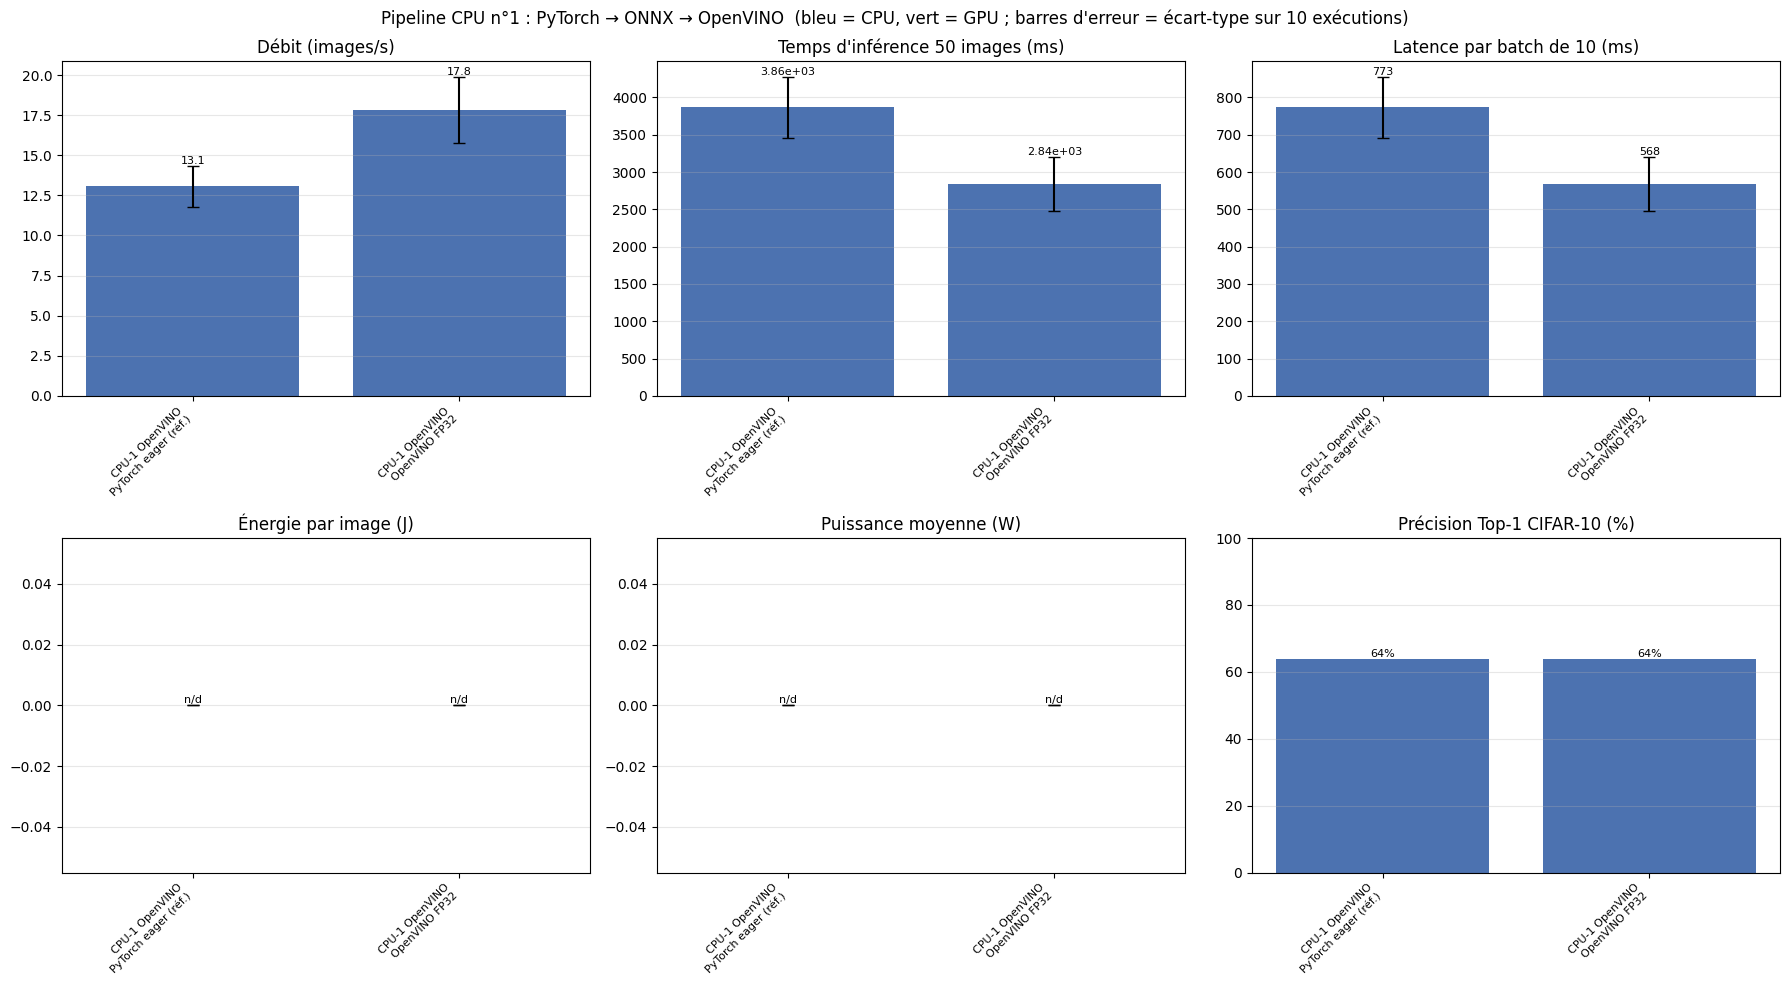

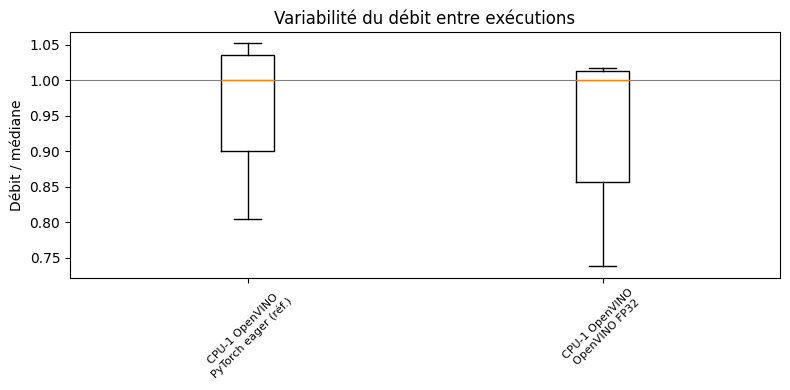

,0,1
pipeline,CPU-1 OpenVINO,CPU-1 OpenVINO
variant,PyTorch eager (réf.),OpenVINO FP32
throughput_mean,13.0581,17.8267
throughput_std,1.2887,2.0415
throughput_min,10.9427,14.0677
throughput_max,14.3028,19.3934
throughput_cv_pct,9.8688,11.452
total_ms_mean,3864.9461,2842.0125
total_ms_std,405.1235,362.1569
total_ms_min,3495.8206,2578.1962


Résultats écrits dans results/01_cpu_openvino.json


[résultats 01_cpu_openvino intégrés au notebook]

In [9]:
df = C.plot_summary(results, "Pipeline CPU n°1 : PyTorch → ONNX → OpenVINO", "figures/01_cpu_openvino.png")
display(df[C.TABLE_COLS].round(4).T)
path = C.save_results("01_cpu_openvino", results, {"openvino": ov.__version__})

In [10]:
# Colab dans le navigateur : télécharge le JSON (à déposer dans results/ du dépôt).
# Extension Colab de VS Code : rien à faire, il suffit d'enregistrer le notebook (résultats intégrés ci-dessus).
try:
    from google.colab import files
    files.download(path)
except Exception:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Lecture des résultats
- **Débit / temps** : comparer chaque variante à la référence *eager* de ce notebook (même machine, même session).
- **Stabilité** : un coefficient de variation (`throughput_cv_pct`) < 5 % indique des mesures reproductibles ; au-delà, regarder le *boxplot* (valeurs aberrantes = interférences de la VM partagée).
- **Qualité** : `agreement_vs_eager` doit valoir 100 % et `max_abs_diff_vs_eager` rester faible (~1e-4 en FP32).
- L'analyse croisée des 4 pipelines est faite dans `05_comparaison.ipynb` et dans le rapport.